# WattWise Energy Analytics
## Machine Learning: Household Electricity Consumption Forecasting

### Project Objective
Develop and evaluate machine learning models to predict household
electricity demand one hour ahead using historical consumption data.

### Machine Learning Workflow
1. Data loading and validation
2. Feature engineering
3. Chronological train-test splitting
4. Baseline model development
5. Machine learning model training
6. Model evaluation and comparison
7. Export predictions for Tableau Public

In [23]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [25]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import HistGradientBoostingRegressor

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Locate the repository's root folder
project_root = Path.cwd()

if project_root.name == "jupyter_notebooks":
    project_root = project_root.parent

# Load the cleaned dataset
file_path = project_root / "cleaned_data_power_consumption.txt"

df = pd.read_csv(file_path, parse_dates=["datetime"])

# Sort chronologically
df = df.sort_values("datetime").reset_index(drop=True)

# Preview
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (34168, 8)


,datetime,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
0,2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,0.5278,16.8611
1,2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,6.7167,16.8667
2,2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,1.4333,16.6833
3,2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,16.7833
4,2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,0.4167,17.2167


## Data Validation

Before developing the forecasting model, we validate the dataset
to identify missing values, duplicate timestamps, and gaps in
the hourly observations.

This helps ensure the reliability of our machine learning features.

In [27]:
# Check data types
print("DATA TYPES")
print(df.dtypes)

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate timestamps
print("\nDUPLICATE TIMESTAMPS")
print(df["datetime"].duplicated().sum())

# Check date range
print("\nDATE RANGE")
print("Start:", df["datetime"].min())
print("End:", df["datetime"].max())

# Check missing hourly timestamps
expected_hours = pd.date_range(
    start=df["datetime"].min(),
    end=df["datetime"].max(),
    freq="h"
)

missing_hours = expected_hours.difference(
    pd.DatetimeIndex(df["datetime"])
)

print("\nMISSING HOURLY TIMESTAMPS")
print(len(missing_hours))

DATA TYPES
datetime                 datetime64[us]
global_active_power             float64
global_reactive_power           float64
voltage                         float64
global_intensity                float64
sub_metering_1                  float64
sub_metering_2                  float64
sub_metering_3                  float64
dtype: object

MISSING VALUES
datetime                 0
global_active_power      0
global_reactive_power    0
voltage                  0
global_intensity         0
sub_metering_1           0
sub_metering_2           0
sub_metering_3           0
dtype: int64

DUPLICATE TIMESTAMPS
0

DATE RANGE
Start: 2006-12-16 17:00:00
End: 2010-11-26 21:00:00

MISSING HOURLY TIMESTAMPS
421


## Feature Engineering

We create calendar and lag features to capture temporal patterns
and historical electricity consumption.

The target variable is `global_active_power`, measured in kilowatts (kW).

Lag features are constructed using actual hourly timestamps to avoid
mistaking missing observations for consecutive hours.

In [28]:
# Create a copy of the dataset
ml_df = df.copy()

# Use datetime as the index
ml_df = ml_df.set_index("datetime").sort_index()

# Restore the complete hourly timeline
ml_df = ml_df.asfreq("h")

# Create calendar features
ml_df["hour"] = ml_df.index.hour
ml_df["day_of_week"] = ml_df.index.dayofweek
ml_df["month"] = ml_df.index.month
ml_df["is_weekend"] = (ml_df["day_of_week"] >= 5).astype(int)

# Create historical consumption features
ml_df["lag_1h"] = ml_df["global_active_power"].shift(1)
ml_df["lag_24h"] = ml_df["global_active_power"].shift(24)
ml_df["lag_168h"] = ml_df["global_active_power"].shift(168)

# Previous 24-hour average, excluding the current hour
ml_df["rolling_mean_24h"] = (
    ml_df["global_active_power"]
    .shift(1)
    .rolling(window=24, min_periods=24)
    .mean()
)

# Select the features for modelling
features = [
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1h",
    "lag_24h",
    "lag_168h",
    "rolling_mean_24h"
]

target = "global_active_power"

# Keep observations with complete features and target
model_df = ml_df.dropna(subset=features + [target]).copy()

print("Original dataset:", df.shape)
print("Model-ready dataset:", model_df.shape)

display(model_df[features + [target]].head())

Original dataset: (34168, 8)
Model-ready dataset: (33387, 15)


,hour,day_of_week,month,is_weekend,lag_1h,lag_24h,lag_168h,rolling_mean_24h,global_active_power
datetime,,,,,,,,,
2006-12-23 17:00:00,17,5,12,1,4.3491,1.4968,4.2229,2.934900,5.4525
2006-12-23 18:00:00,18,5,12,1,5.4525,2.6870,3.6322,3.099721,3.8794
2006-12-23 19:00:00,19,5,12,1,3.8794,3.9382,3.4002,3.149404,4.1178
2006-12-23 20:00:00,20,5,12,1,4.1178,3.5361,3.2686,3.156887,4.1814
2006-12-23 21:00:00,21,5,12,1,4.1814,4.5487,3.0565,3.183775,3.2884


## Model Training and Evaluation

The dataset is divided chronologically into training (80%)
and testing (20%) sets.

A chronological split preserves the order of observations
and prevents the model from being trained on future target values.

Model performance will be evaluated using MAE, RMSE and R².

In [29]:
# Define features and target
X = model_df[features]
y = model_df[target]

# Chronological 80/20 split
split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting period:")
print(X_test.index.min(), "to", X_test.index.max())

Training observations: 26709
Testing observations: 6678

Training period:
2006-12-23 17:00:00 to 2010-01-29 17:00:00

Testing period:
2010-01-29 18:00:00 to 2010-11-26 21:00:00


In [30]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Seasonal naive baseline
baseline_predictions = X_test["lag_168h"]

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

print("BASELINE MODEL PERFORMANCE")
print(f"MAE: {baseline_mae:.4f} kW")
print(f"RMSE: {baseline_rmse:.4f} kW")
print(f"R²: {baseline_r2:.4f}")

BASELINE MODEL PERFORMANCE
MAE: 0.5681 kW
RMSE: 0.8197 kW
R²: -0.1862


In [31]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Initialise the model
ml_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

# Train the model
ml_model.fit(X_train, y_train)

# Generate predictions
ml_predictions = ml_model.predict(X_test)

# Calculate evaluation metrics
ml_mae = mean_absolute_error(y_test, ml_predictions)
ml_rmse = np.sqrt(mean_squared_error(y_test, ml_predictions))
ml_r2 = r2_score(y_test, ml_predictions)

print("MACHINE LEARNING MODEL PERFORMANCE")
print(f"MAE: {ml_mae:.4f} kW")
print(f"RMSE: {ml_rmse:.4f} kW")
print(f"R²: {ml_r2:.4f}")

MACHINE LEARNING MODEL PERFORMANCE
MAE: 0.3332 kW
RMSE: 0.4803 kW
R²: 0.5928


In [32]:
# Create a DataFrame for model predictions
results_df = pd.DataFrame({
    "datetime": y_test.index,
    "actual_power_kw": y_test.to_numpy(),
    "predicted_power_kw": ml_predictions,
    "baseline_power_kw": baseline_predictions.to_numpy()
})

results_df["absolute_error_kw"] = (
    results_df["actual_power_kw"] -
    results_df["predicted_power_kw"]
).abs()

display(results_df.head())

,datetime,actual_power_kw,predicted_power_kw,baseline_power_kw,absolute_error_kw
0,2010-01-29 18:00:00,1.8160,2.394213,1.8303,0.578213
1,2010-01-29 19:00:00,0.4448,2.293137,1.7350,1.848337
2,2010-01-29 20:00:00,0.4278,0.991720,1.1318,0.563920
3,2010-01-29 21:00:00,0.2927,0.912300,1.4664,0.619600
4,2010-01-29 22:00:00,0.4056,0.559692,2.8046,0.154092


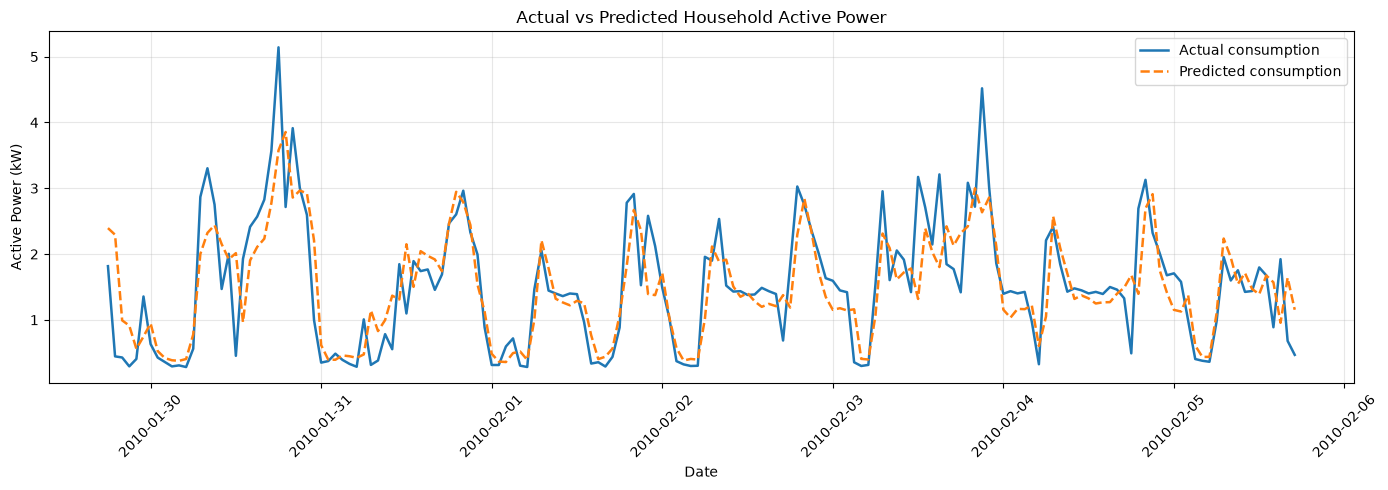

In [33]:
import matplotlib.pyplot as plt

# Display the first 168 test observations
plot_df = results_df.head(168)

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["datetime"],
    plot_df["actual_power_kw"],
    label="Actual consumption",
    linewidth=1.8
)

plt.plot(
    plot_df["datetime"],
    plot_df["predicted_power_kw"],
    label="Predicted consumption",
    linewidth=1.8,
    linestyle="--"
)

plt.title("Actual vs Predicted Household Active Power")
plt.xlabel("Date")
plt.ylabel("Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
# Compare baseline and machine learning performance

comparison_df = pd.DataFrame({
    "Model": [
        "Seasonal Naive Baseline",
        "Gradient Boosting"
    ],
    "MAE (kW)": [
        baseline_mae,
        ml_mae
    ],
    "RMSE (kW)": [
        baseline_rmse,
        ml_rmse
    ],
    "R2": [
        baseline_r2,
        ml_r2
    ]
})

# Display the comparison
display(comparison_df.round(4))

,Model,MAE (kW),RMSE (kW),R2
0,Seasonal Naive Baseline,0.5681,0.8197,-0.1862
1,Gradient Boosting,0.3332,0.4803,0.5928


In [35]:
from pathlib import Path

# Locate project root
project_root = Path.cwd()

if project_root.name == "jupyter_notebooks":
    project_root = project_root.parent

# Create output folder
output_dir = project_root / "ml_outputs"
output_dir.mkdir(exist_ok=True)

# Export predictions
results_df.to_csv(
    output_dir / "electricity_predictions.csv",
    index=False
)

# Export model comparison
comparison_df.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

print("Tableau-ready CSV files exported successfully.")

Tableau-ready CSV files exported successfully.


### Actual vs Predicted Electricity Consumption

The actual-versus-predicted chart shows that the Gradient Boosting model captures the general hourly fluctuations in household electricity demand.

**Key Findings:**

- **Consumption Patterns:** Predicted values closely follow several consumption peaks and low-demand periods.
- **Underestimation:** The model sometimes underestimates sudden spikes in electricity demand.
- **Overestimation:** The model occasionally overestimates consumption during low-usage periods.

**Model Performance:**

| Metric | Value |
|--------|-------|
| Mean Absolute Error (MAE) | 0.3332 kW |
| Root Mean Squared Error (RMSE) | 0.4803 kW |
| R² Score | 0.5928 |

**Conclusion:**

The Gradient Boosting model outperformed the seasonal naïve baseline, reducing MAE by approximately **41.3%** and RMSE by **41.4%**.

These findings suggest that historical electricity consumption and calendar features are useful for one-hour-ahead demand prediction. However, forecasting sudden changes in consumption remains challenging.